In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791266160.428625    1668 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791266160.686516    1668 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791266162.182392    1668 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
TRAIN_DIR = "/mnt/c/Users/sagni/EMO-Recognition/Datasets/train"
TEST_DIR = "/mnt/c/Users/sagni/EMO-Recognition/Datasets/test"

class_names = sorted(os.listdir(TRAIN_DIR))
NUM_CLASSES = len(class_names)

print("Classes:", class_names)

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [3]:
BATCH = 64
VAL_SPLIT = 0.1

common = dict(
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    image_size=(48, 48),
    batch_size=None
)

raw_train = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    shuffle=True,
    **common
)

raw_val = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    shuffle=True,
    **common
)

raw_test = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    shuffle=False,
    **common
)

def prepare(ds, training=False):
    ds = ds.cache()

    if training:
        ds = ds.shuffle(5000, seed=SEED)

    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = prepare(raw_train, True)
val_ds = prepare(raw_val)
test_ds = prepare(raw_test)

Found 28709 files belonging to 7 classes.
Using 25839 files for training.


I0000 00:00:1791266163.599039    1668 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.


In [4]:
counts = pd.DataFrame({
    "train": [
        len(os.listdir(os.path.join(TRAIN_DIR, c)))
        for c in class_names
    ]
}, index=class_names)

n = counts["train"].values

cw = (n.sum() / (NUM_CLASSES * n)) ** 0.5

class_weight = {
    i: float(w)
    for i, w in enumerate(cw)
}

print("Class weights:")
print({
    class_names[i]: round(w, 2)
    for i, w in class_weight.items()
})

Class weights:
{'angry': 1.01, 'disgust': 3.07, 'fear': 1.0, 'happy': 0.75, 'neutral': 0.91, 'sad': 0.92, 'surprise': 1.14}


In [5]:
def augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.15, value_range=(0, 255))
    ])

In [6]:
IMG_SIZE = 224
def build_resnet50():
    inp = keras.Input((48, 48, 3))
    x = augmentation()(inp)
    x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)
    x = keras.applications.resnet50.preprocess_input(x)
    base = keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3)
    )
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)
    model = keras.Model(inp, out)
    return model, base
model, base = build_resnet50()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 48, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 48, 48, 3) │          0 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 224, 224,  │          0 │ sequential[0][0]  │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ resizing[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ resizing[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7)         │      1,799 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,114,055 (91.99 MB)

 Trainable params: 526,343 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/12


/home/sagnik/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791266178.257513    1749 cuda_dnn.cc:461] Loaded cuDNN version 92700


404/404 ━━━━━━━━━━━━━━━━━━━━ 96s 205ms/step - accuracy: 0.3796 - loss: 1.6035 - val_accuracy: 0.4578 - val_loss: 1.4251 - learning_rate: 0.0010
Epoch 2/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 87s 215ms/step - accuracy: 0.4290 - loss: 1.4853 - val_accuracy: 0.4742 - val_loss: 1.3624 - learning_rate: 0.0010
Epoch 3/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 95s 236ms/step - accuracy: 0.4511 - loss: 1.4361 - val_accuracy: 0.4794 - val_loss: 1.3666 - learning_rate: 0.0010
Epoch 4/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 99s 246ms/step - accuracy: 0.4599 - loss: 1.4078 - val_accuracy: 0.4983 - val_loss: 1.3455 - learning_rate: 0.0010
Epoch 5/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 101s 249ms/step - accuracy: 0.4658 - loss: 1.3907 - val_accuracy: 0.5118 - val_loss: 1.2788 - learning_rate: 0.0010
Epoch 6/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 94s 232ms/step - accuracy: 0.4735 - loss: 1.3661 - val_accuracy: 0.5101 - val_loss: 1.2713 - learning_rate: 0.0010
Epoch 7/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 84s 208ms/step - accuracy: 0.4804 - loss

In [8]:
print(
    "Best Stage 1 validation accuracy:",
    max(history1.history["val_accuracy"])
)

Best Stage 1 validation accuracy: 0.5376306772232056


In [9]:
base.trainable = True

# Freeze everything except the last 40 layers
for layer in base.layers[:-40]:
    layer.trainable = False

# Keep BatchNorm frozen
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base.layers)
)

Trainable layers: 28


In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/25


/home/sagnik/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


404/404 ━━━━━━━━━━━━━━━━━━━━ 115s 262ms/step - accuracy: 0.5020 - loss: 1.3180 - val_accuracy: 0.5516 - val_loss: 1.1663 - learning_rate: 1.0000e-04
Epoch 2/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 99s 244ms/step - accuracy: 0.5563 - loss: 1.1791 - val_accuracy: 0.5875 - val_loss: 1.0993 - learning_rate: 1.0000e-04
Epoch 3/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 96s 237ms/step - accuracy: 0.5885 - loss: 1.1060 - val_accuracy: 0.5899 - val_loss: 1.0826 - learning_rate: 1.0000e-04
Epoch 4/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 96s 237ms/step - accuracy: 0.6143 - loss: 1.0327 - val_accuracy: 0.6244 - val_loss: 1.0154 - learning_rate: 1.0000e-04
Epoch 5/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 95s 236ms/step - accuracy: 0.6313 - loss: 0.9767 - val_accuracy: 0.6035 - val_loss: 1.0366 - learning_rate: 1.0000e-04
Epoch 6/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.6542 - loss: 0.9246  
Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
404/404 ━━━━━━━━━━━━━━━━━━━━ 95s 236ms/step - acc

In [1]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history1.history["accuracy"], label="Stage 1 Train")
plt.plot(history1.history["val_accuracy"], label="Stage 1 Val")

plt.plot(
    range(
        len(history1.history["accuracy"]),
        len(history1.history["accuracy"]) + len(history2.history["accuracy"])
    ),
    history2.history["accuracy"],
    label="Stage 2 Train"
)

plt.plot(
    range(
        len(history1.history["val_accuracy"]),
        len(history1.history["val_accuracy"]) + len(history2.history["val_accuracy"])
    ),
    history2.history["val_accuracy"],
    label="Stage 2 Val"
)

plt.title("ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(history1.history["loss"], label="Stage 1 Train")
plt.plot(history1.history["val_loss"], label="Stage 1 Val")

plt.plot(
    range(
        len(history1.history["loss"]),
        len(history1.history["loss"]) + len(history2.history["loss"])
    ),
    history2.history["loss"],
    label="Stage 2 Train"
)

plt.plot(
    range(
        len(history1.history["val_loss"]),
        len(history1.history["val_loss"]) + len(history2.history["val_loss"])
    ),
    history2.history["val_loss"],
    label="Stage 2 Val"
)

plt.title("ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [14]:
model.save("/mnt/c/Users/sagni/EMO-Recognition/Models/resnet50.keras")

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 172ms/step - accuracy: 0.6721 - loss: 1.0587
Test Loss: 1.058703899383545
Test Accuracy: 0.6720535159111023


In [18]:
# Generate fresh predictions from ResNet50
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       angry       0.62      0.58      0.60       958
     disgust       0.74      0.60      0.67       111
        fear       0.55      0.46      0.50      1024
       happy       0.89      0.84      0.86      1774
     neutral       0.57      0.72      0.64      1233
         sad       0.55      0.55      0.55      1247
    surprise       0.78      0.81      0.79       831

    accuracy                           0.67      7178
   macro avg       0.67      0.65      0.66      7178
weighted avg       0.68      0.67      0.67      7178



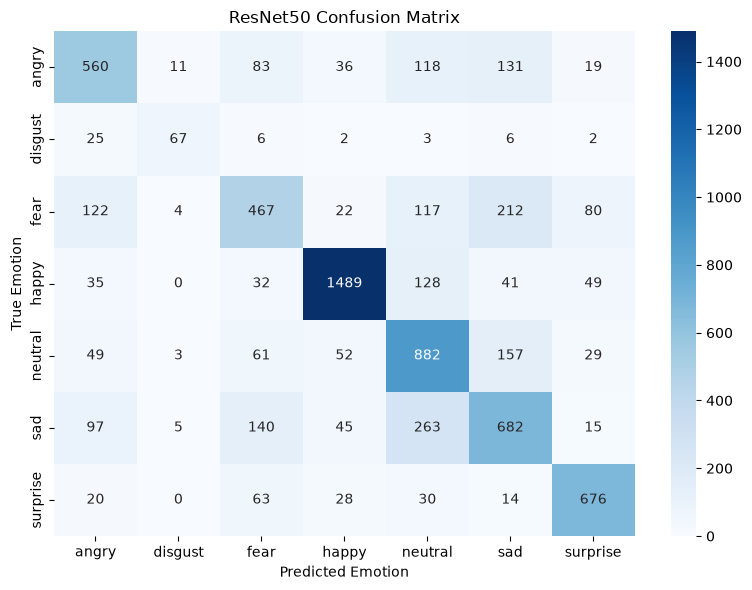

In [19]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.title("ResNet50 Confusion Matrix")

plt.tight_layout()
plt.show()